# Post-Merge Reality (Agents in the Wild)
**Paper:** Xia & Miller 2026 – Do These Violent Delights Have Violent Ends? Measuring the Post-Merge Fate of Agentic Code
**Data:** https://github.com/post-merge-reality/post-merge-reality

**What is in the data:** 182 repositories with agent PRs (May 2025 → May 2026). Every line added by an **AI-co-authored commit** or a **human commit** is followed until a later commit changes it. Each later commit gets a maintenance class: **corrective (= fix)**, adaptive, perfective, preventive, management.

**One row of the main table =** one origin commit (AI or human) with what happened to its lines later

This notebook has 3 parts:
1. **First look** – the files, some lines, all the columns, the size.
2. **Data-science view** – size, dates, **numbers per AI agent**, **how the agent is involved** (tables saved in `tables/`).
3. **Charts** – what kind of change · fixes per AI agent · who wrote the fix · how fast the fix comes · extra (saved in `charts/`).

In [1]:
import sys, os, json
sys.path.insert(0, "../..")          # to find common.py in the parent folder
from common import *

## 0. Get the data
(The full raw data is very big and not public yet; the repository ships the analysis tables, which we use here.)

In [2]:
root = get_repo("https://github.com/post-merge-reality/post-merge-reality", "post-merge-reality")
A = os.path.join(root, "dev", "analysis")

Data folder: ../../data/02_XiaMiller_PostMerge/post-merge-reality


## 1. First look
### Files in the repository

In [3]:
list_files(root).head(20)

,file,size_MB
0,dev/analysis/output_rq1b_explore/rq1b_origin_commit_term...,15.13
1,filtered_full_sample_repos.csv,0.03
2,dev/analysis/output_rq1a_explore/rq1_origin_to_terminal_...,0.00


### Table 1: the 182 repositories

In [4]:
repos = pd.read_csv(os.path.join(root, "filtered_full_sample_repos.csv"))
_ = overview(repos, "Repositories")

**Repositories** — **182 rows × 21 columns** (0.0 MB in memory)

*First 5 lines:*

,repo_slug,repo_url,num_forks,num_watchers,num_stars,primary_language,num_PRs,num_PRs_human,num_PRs_agent,num_PRs_bot,num_months_with_agentic_PRs,filter_passed,filter_reason,min_monthly_commits_observed,branch_checked,commits_2025-12,commits_2026-01,commits_2026-02,commits_2026-03,commits_2026-04,commits_2026-05
0,benwbrum/fromthepage,https://github.com/benwbrum/fromthepage,53,11,179,Ruby,1980,1796,137,47,9,1,passed,53,auto,109,120,76,124,94,53
1,readthedocs/readthedocs.org,https://github.com/readthedocs/readthedocs.org,3681,237,8279,Python,3884,3636,60,188,5,1,passed,19,auto,40,34,57,48,80,19
2,XRPLF/rippled,https://github.com/XRPLF/rippled,1577,514,5034,C++,2369,2352,12,5,4,1,passed,21,auto,21,53,52,131,73,80
3,Azure/azure-sdk-for-python,https://github.com/Azure/azure-sdk-for-python,3174,512,5395,Python,26251,24025,179,2047,10,1,passed,147,auto,166,147,222,232,238,209
4,fjordllc/bootcamp,https://github.com/fjordllc/bootcamp,75,76,294,Ruby,4098,3673,11,414,4,1,passed,234,auto,344,234,397,294,313,371


*All columns:*

,column,type,missing_%,unique,example
0,repo_slug,str,0.0,182,benwbrum/fromthepage
1,repo_url,str,0.0,182,https://github.com/benwbrum/fromthepage
2,num_forks,int64,0.0,157,53
3,num_watchers,int64,0.0,100,11
4,num_stars,int64,0.0,169,179
5,primary_language,str,0.5,25,Ruby
6,num_PRs,int64,0.0,181,1980
7,num_PRs_human,int64,0.0,178,1796
8,num_PRs_agent,int64,0.0,82,137
9,num_PRs_bot,int64,0.0,152,47


### Table 2 (main): each origin commit and what happened to its lines

In [5]:
orig = pd.read_csv(pick(os.path.join(A, "output_rq1b_explore", "rq1b_origin_commit_terminal_maintenance_summary.csv")))
_ = overview(orig, "Origin commits")

**Origin commits** — **247,348 rows × 30 columns** (105.2 MB in memory)

*First 5 lines:*

,repo_key,repo,origin_commit_sha,origin_role,origin_commit_category,origin_commit_date,tracked_line_count,survived_line_count,terminated_line_count,any_termination,termination_rate,first_termination_date,first_termination_days,first_terminal_commit_sha,first_terminal_maintenance_class,mode_terminal_maintenance_class,terminal_corrective_line_count,terminal_adaptive_line_count,terminal_perfective_line_count,terminal_preventive_line_count,terminal_management_line_count,terminal_unknown_line_count,terminal_mixed_line_count,terminal_corrective_commit_count,terminal_adaptive_commit_count,terminal_perfective_commit_count,terminal_preventive_commit_count,terminal_management_commit_count,terminal_unknown_commit_count,terminal_mixed_commit_count
0,benwbrum__fromthepage,benwbrum/fromthepage,456e850f4b27aca7cfc7a48ae712273de88ae4af,Human,not_ai_coauthored,2025-05-06T04:04:34+08:00,107,92,15,1,0.140187,2025-05-07T00:50:58+08:00,0.865556,cdef8ae829f4a2b57958503101c424d4a31a2c21,preventive,preventive,1,4,0,8,2,0,0,1,1,0,4,1,0,0
1,benwbrum__fromthepage,benwbrum/fromthepage,9e19824eab503422df4f57e518eab7ddff99a218,Human,not_ai_coauthored,2025-05-06T08:50:18-05:00,2,2,0,0,0.000000,NaN,NaN,NaN,NaN,NaN,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,benwbrum__fromthepage,benwbrum/fromthepage,cdef8ae829f4a2b57958503101c424d4a31a2c21,Human,not_ai_coauthored,2025-05-07T00:50:58+08:00,9,4,5,1,0.555556,2025-05-07T01:39:26+08:00,0.033657,050971a43a211bf0eda9c3610dddb65fe51337a8,perfective,perfective,0,0,5,0,0,0,0,0,0,1,0,0,0,0
3,benwbrum__fromthepage,benwbrum/fromthepage,050971a43a211bf0eda9c3610dddb65fe51337a8,Human,not_ai_coauthored,2025-05-07T01:39:26+08:00,30,30,0,0,0.000000,NaN,NaN,NaN,NaN,NaN,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,benwbrum__fromthepage,benwbrum/fromthepage,2fb6d9baf260d981f2d84bde0ae133ef71cd7c16,Human,not_ai_coauthored,2025-05-08T09:45:54-05:00,8,3,5,1,0.625000,2025-05-08T10:20:05-05:00,0.023738,9bffb1159e57dce70cf2faf2c49a40a235e36a88,management,management,0,0,3,1,1,0,0,0,0,1,1,1,0,0


*All columns:*

,column,type,missing_%,unique,example
0,repo_key,str,0.0,182,benwbrum__fromthepage
1,repo,str,0.0,182,benwbrum/fromthepage
2,origin_commit_sha,str,0.0,247271,456e850f4b27aca7cfc7a48ae712273de88ae4af
3,origin_role,str,0.0,2,Human
4,origin_commit_category,str,0.0,2,not_ai_coauthored
5,origin_commit_date,str,0.0,221631,2025-05-06T04:04:34+08:00
6,tracked_line_count,int64,0.0,5453,107
7,survived_line_count,int64,0.0,4461,92
8,terminated_line_count,int64,0.0,3035,15
9,any_termination,int64,0.0,2,1


### Table 3: who changed the lines (AI / human / bot)

In [6]:
flow = pd.read_csv(os.path.join(A, "output_rq1a_explore", "rq1_origin_to_terminal_actor_flow.csv"))
_ = overview(flow, "Line flow", n=10)

**Line flow** — **10 rows × 10 columns** (0.0 MB in memory)

*First 10 lines:*

,origin_role,terminal_actor,terminal_actor_label,line_count,role_total_line_count,terminal_actor_total_line_count,grand_total_line_count,percent_within_origin_role,percent_within_terminal_actor,percent_of_all_tracked_lines
0,AI,terminated_by_ai,Terminated by AI commit,1506549,13983714,3376304,77157916,0.107736,0.446212,0.019526
1,AI,terminated_by_human,Terminated by Human commit,1705683,13983714,19454557,77157916,0.121976,0.087675,0.022106
2,AI,terminated_by_bot,Terminated by bot commit,167540,13983714,2311635,77157916,0.011981,0.072477,0.002171
3,AI,survived,Survived,10603942,13983714,52015420,77157916,0.758307,0.203862,0.137432
4,AI,terminated_by_unknown,Terminated by unknown commit,0,13983714,0,77157916,0.000000,0.000000,0.000000
5,Human,terminated_by_ai,Terminated by AI commit,1869755,63174202,3376304,77157916,0.029597,0.553788,0.024233
6,Human,terminated_by_human,Terminated by Human commit,17748874,63174202,19454557,77157916,0.280951,0.912325,0.230033
7,Human,terminated_by_bot,Terminated by bot commit,2144095,63174202,2311635,77157916,0.033939,0.927523,0.027788
8,Human,survived,Survived,41411478,63174202,52015420,77157916,0.655512,0.796138,0.536711
9,Human,terminated_by_unknown,Terminated by unknown commit,0,63174202,0,77157916,0.000000,0.000000,0.000000


*All columns:*

,column,type,missing_%,unique,example
0,origin_role,str,0.0,2,AI
1,terminal_actor,str,0.0,5,terminated_by_ai
2,terminal_actor_label,str,0.0,5,Terminated by AI commit
3,line_count,int64,0.0,9,1506549
4,role_total_line_count,int64,0.0,2,13983714
5,terminal_actor_total_line_count,int64,0.0,5,3376304
6,grand_total_line_count,int64,0.0,1,77157916
7,percent_within_origin_role,float64,0.0,9,0.1077359705726247
8,percent_within_terminal_actor,float64,0.0,9,0.4462124856055616
9,percent_of_all_tracked_lines,float64,0.0,9,0.0195255273613144


## 2. Data-science view
### Size and dates

In [7]:
orig["date"] = pd.to_datetime(orig["origin_commit_date"], utc=True, errors="coerce")
print("Repositories          :", len(repos))
print("PRs in these repos    :", f"{repos['num_PRs'].sum():,}", "| by agents:", f"{repos['num_PRs_agent'].sum():,}")
print("Origin commits        :", f"{len(orig):,}", "| AI-co-authored:", f"{(orig.origin_role == 'AI').sum():,}")
print("Tracked lines         :", f"{orig['tracked_line_count'].sum():,}")
print("Dates                 :", orig["date"].min().date(), "->", orig["date"].max().date())

Repositories          : 182
PRs in these repos    : 682,970 | by agents: 10,519
Origin commits        : 247,348 | AI-co-authored: 29,100
Tracked lines         : 77,157,916
Dates                 : 2025-05-01 -> 2026-05-31


### Numbers per AI agent
⚠️ The released tables only say **AI vs human** (an AI commit = a commit with an agent co-author, e.g. `Co-authored-by: Claude`). The **name of the agent is not in the released data** (it is in the raw data, not public yet). So we show the numbers per **origin role** and per **repository language**.

In [8]:
orig["fixed_later"] = orig["terminal_corrective_commit_count"] > 0
per_role = orig.groupby("origin_role").agg(commits=("origin_commit_sha", "size"), tracked_lines=("tracked_line_count", "sum"),
            commits_fixed_later=("fixed_later", "sum"), median_days_to_first_change=("first_termination_days", "median"))
per_role["fixed_later_%"] = (100 * per_role["commits_fixed_later"] / per_role["commits"]).round(1)
save_table(per_role.reset_index(), "per_role")
per_role

,commits,tracked_lines,commits_fixed_later,median_days_to_first_change,fixed_later_%
origin_role,,,,,
AI,29100,13983714,7822,2.036424,26.9
Human,218248,63174202,56385,4.110972,25.8


In [9]:
lang = repos.groupby("primary_language").agg(repos=("repo_slug", "size"), agent_PRs=("num_PRs_agent", "sum"), all_PRs=("num_PRs", "sum")).sort_values("agent_PRs", ascending=False)
save_table(lang.reset_index(), "per_language")
lang

,repos,agent_PRs,all_PRs
primary_language,,,
TypeScript,57,2869,216974
Python,25,1827,84182
Rust,13,807,68064
HTML,5,704,23745
JavaScript,7,704,18954
C#,16,548,44260
C,4,378,12956
Go,14,376,36065
Ruby,4,264,19131


### How the agent is involved
The agent is a **co-author of commits** (detected from the commit author / `Co-authored-by` line). Later, the lines are changed by an **AI commit, a human commit or a bot**:

In [10]:
inv = flow.pivot(index="origin_role", columns="terminal_actor_label", values="percent_within_origin_role").mul(100).round(1)
save_table(inv.reset_index(), "who_changes_lines_pct")
inv

terminal_actor_label,Survived,Terminated by AI commit,Terminated by Human commit,Terminated by bot commit,Terminated by unknown commit
origin_role,,,,,
AI,75.8,10.8,12.2,1.2,0.0
Human,65.6,3.0,28.1,3.4,0.0


In [11]:
summary_card("Xia & Miller 2026", "origin commit (AI or human)", len(orig), len(repos), str(orig["date"].min().date()),
             str(orig["date"].max().date()), "15 agents (names not in released tables)", "Agent co-authors commits; lines later changed by AI, human or bot",
             int(orig.query("origin_role == 'AI'")["fixed_later"].sum()))

,
paper,Xia & Miller 2026
unit (1 row =),origin commit (AI or human)
rows,247348
repos,182
first date,2025-05-01
latest date,2026-05-31
agents,15 agents (names not in released tables)
how the agent is involved,"Agent co-authors commits; lines later changed by AI, hum..."
fixes of AI code,7822


,paper,unit (1 row =),rows,repos,first date,latest date,agents,how the agent is involved,fixes of AI code
0,Xia & Miller 2026,origin commit (AI or human),247348,182,2025-05-01,2026-05-31,15 agents (names not in released tables),"Agent co-authors commits; lines later changed by AI, hum...",7822


## 3. Charts
### Chart 1 · What kind of change comes first after AI code (vs human code)

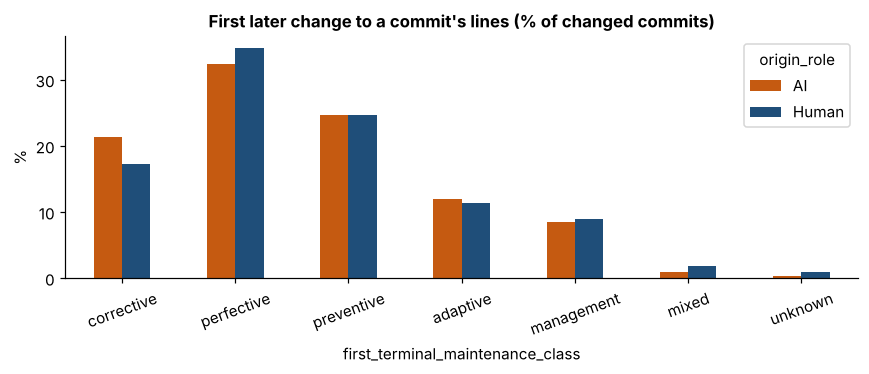

In [12]:
k = pd.crosstab(orig["origin_role"], orig["first_terminal_maintenance_class"], normalize="index").mul(100).round(1)
k = k[[c for c in ["corrective", "perfective", "preventive", "adaptive", "management", "mixed", "unknown"] if c in k]]
save_table(k.reset_index(), "first_change_class_pct")
fig, ax = plt.subplots(figsize=(8, 3.5)); k.T.plot(kind="bar", ax=ax, color=[ORANGE, BLUE])
ax.set_title("First later change to a commit's lines (% of changed commits)"); ax.set_ylabel("%"); plt.xticks(rotation=20)
save_chart(fig, "1_first_change_class.png")

### Chart 2 · AI commits that were fixed later, per repository language
(per agent is not possible with the released tables)

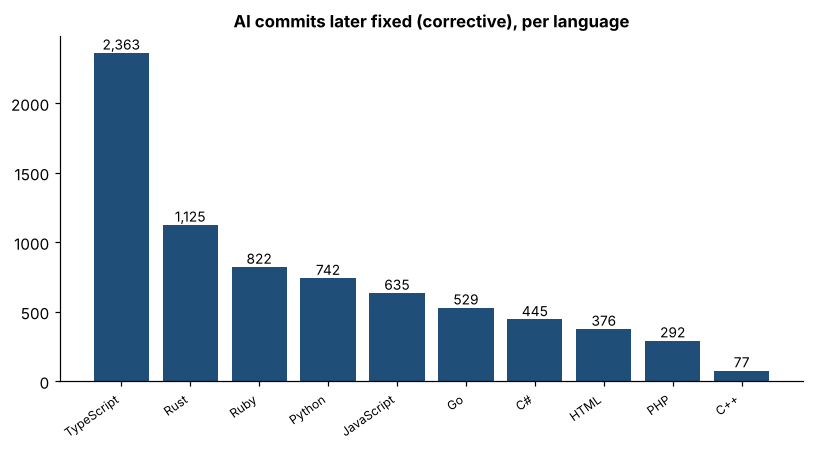

*Exact numbers – AI commits later fixed (corrective), per language*

,number,%
primary_language,,
TypeScript,2363.0,31.9
Rust,1125.0,15.2
Ruby,822.0,11.1
Python,742.0,10.0
JavaScript,635.0,8.6
Go,529.0,7.1
C#,445.0,6.0
HTML,376.0,5.1
PHP,292.0,3.9


In [13]:
ai = orig[orig.origin_role == "AI"].merge(repos[["repo_slug", "primary_language"]], left_on="repo", right_on="repo_slug", how="left")
bar(ai[ai.fixed_later]["primary_language"].value_counts().head(10), "AI commits later fixed (corrective), per language", "2_fixed_per_language.png", horizontal=True)

### Chart 3 · Who changes the lines written by AI

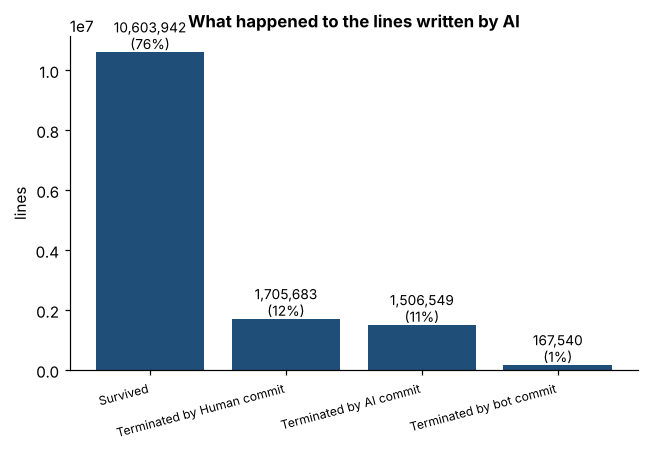

*Exact numbers – What happened to the lines written by AI*

,number,%
terminal_actor_label,,
Survived,10603942.0,75.8
Terminated by Human commit,1705683.0,12.2
Terminated by AI commit,1506549.0,10.8
Terminated by bot commit,167540.0,1.2
TOTAL,13983714.0,100.0


In [14]:
w = flow[flow.origin_role == "AI"].set_index("terminal_actor_label")["line_count"]
bar(w[w > 0].sort_values(ascending=False), "What happened to the lines written by AI", "3_who_changes_ai_lines.png", "lines", pct=True)

### Chart 4 · How fast the first fix comes

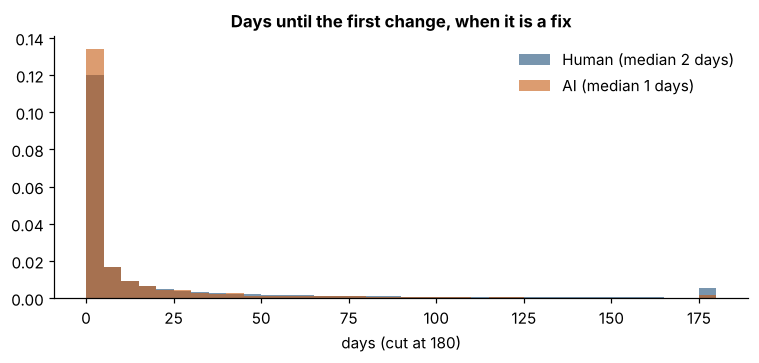

In [15]:
fast = orig[(orig.first_terminal_maintenance_class == "corrective")]
fig, ax = plt.subplots(figsize=(7, 3.4))
for role, c in [("Human", BLUE), ("AI", ORANGE)]:
    x = fast[fast.origin_role == role]["first_termination_days"]
    ax.hist(x.clip(upper=180), bins=36, alpha=0.6, color=c, density=True, label=f"{role} (median {x.median():.0f} days)")
ax.set_title("Days until the first change, when it is a fix"); ax.set_xlabel("days (cut at 180)"); ax.legend(frameon=False)
save_chart(fig, "4_days_to_first_fix.png")

### Extra · Agent PRs per repository language

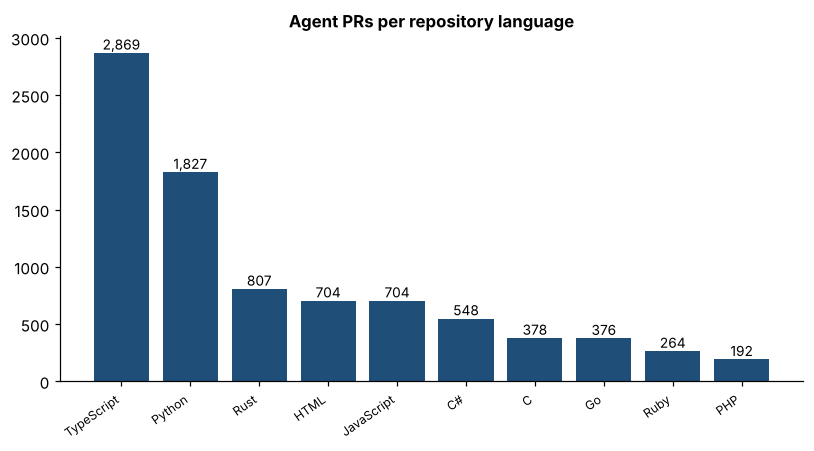

*Exact numbers – Agent PRs per repository language*

,number,%
primary_language,,
TypeScript,2869.0,33.1
Python,1827.0,21.1
Rust,807.0,9.3
HTML,704.0,8.1
JavaScript,704.0,8.1
C#,548.0,6.3
C,378.0,4.4
Go,376.0,4.3
Ruby,264.0,3.0


In [16]:
bar(lang["agent_PRs"].head(10), "Agent PRs per repository language", "5_agent_prs_language.png", horizontal=True)

## 4. Final figure (the 4 charts on one page)

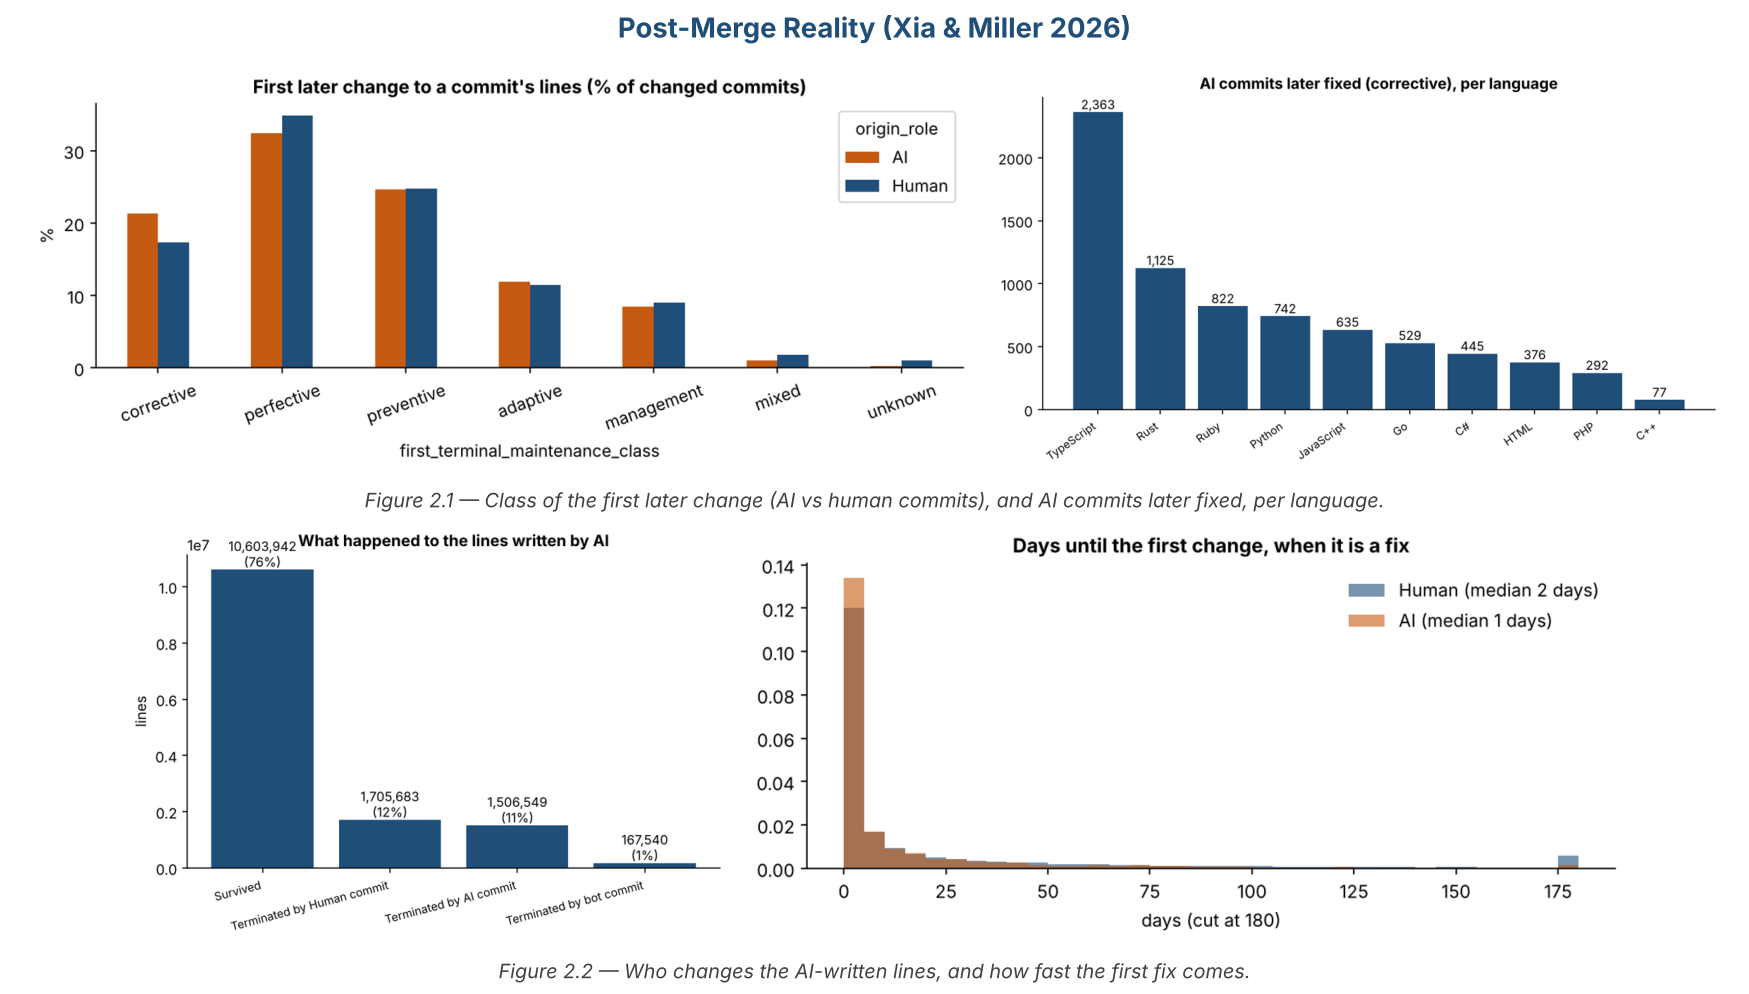

In [17]:
final_figure(2, "Post-Merge Reality (Xia & Miller 2026)",
             "Class of the first later change (AI vs human commits), and AI commits later fixed, per language.",
             "Who changes the AI-written lines, and how fast the first fix comes.")

## 5. The fixes in one common format
Each row = one **AI commit whose lines were later fixed** (a corrective commit). Agent names and who made the fix are not in the released tables.

The notebook `99_ALL_PAPERS_summary` merges this file from every paper into the **final dataset**.

In [18]:
a = ai[ai.fixed_later]
first_fix = a["first_terminal_maintenance_class"] == "corrective"
f = pd.DataFrame({"agent": "AI (name not released)", "repo": a["repo"], "language": a["primary_language"], "level": "commit",
    "ai_change": a["origin_commit_sha"], "fix_change": a["first_terminal_commit_sha"].where(first_fix),
    "fixed_by": "Unknown", "days_to_fix": a["first_termination_days"].where(first_fix),
    "fix_label": "corrective (Swanson class)", "fix_reason": None, "has_code_patch": False})
fixes = save_fixes(f, "Xia & Miller 2026")

**7,822 fixes saved to `tables/fixes.csv`** (same columns in every paper)

,paper,fix_id,agent,repo,language,level,ai_change,fix_change,fixed_by,days_to_fix,fix_label,fix_reason,has_code_patch
11,Xia & Miller 2026,XIA-00000,AI (name not released),benwbrum/fromthepage,Ruby,commit,59830f768240b3de5533e0814c49cf56e2e9b176,317e1de9b16cc55f7629c267f465ff0a23f9c313,Unknown,0.002292,corrective (Swanson class),None,False
18,Xia & Miller 2026,XIA-00001,AI (name not released),benwbrum/fromthepage,Ruby,commit,014432f8af7209a0b9ed82dd910207925cde2e60,45088f85112f56000c9336cc9822c9a9ba75688b,Unknown,0.004213,corrective (Swanson class),None,False
19,Xia & Miller 2026,XIA-00002,AI (name not released),benwbrum/fromthepage,Ruby,commit,45088f85112f56000c9336cc9822c9a9ba75688b,NaN,Unknown,NaN,corrective (Swanson class),None,False
20,Xia & Miller 2026,XIA-00003,AI (name not released),benwbrum/fromthepage,Ruby,commit,aa1724d1a3d9cca3c338f50f23424b3a16e89069,NaN,Unknown,NaN,corrective (Swanson class),None,False
22,Xia & Miller 2026,XIA-00004,AI (name not released),benwbrum/fromthepage,Ruby,commit,510121257097edab78344e8a9f851dc98a25ca5a,NaN,Unknown,NaN,corrective (Swanson class),None,False
